# Machine Learning Assignment 2

**BITS ID:** 2026CT05019  
**Programme:** M.Tech AIML
**Course:** Machine Learning  
**Assignment:** Classification Model Development and Comparative Evaluation

---

## Notebook objective
This notebook presents an end-to-end, machine-learning workflow covering dataset selection, exploratory analysis, leakage-safe preprocessing, implementation of five prescribed classification algorithms, evaluation using six prescribed metrics, graphical comparison, model-wise observations, saved models, exported test data, and the final conclusion.

## 1. Problem Statement

The objective is to build and compare five supervised classification algorithms on a public classification dataset:

1. Logistic Regression
2. Decision Tree
3. k-Nearest Neighbors (kNN)
4. Gaussian Naive Bayes
5. Random Forest

All models are evaluated on the same stratified 80:20 train-test split using **Accuracy, AUC, Precision, Recall, F1 Score, and Matthews Correlation Coefficient (MCC)**. The analysis also examines missing values, duplicate observations, class distribution, scaling, categorical encoding applicability, data-leakage prevention, graphical comparison, and model-specific performance.

## 2. Dataset Selection and Justification

The **Digits dataset**, available through `sklearn.datasets.load_digits`, is used for this multiclass classification study. It is derived from the handwritten digits dataset made available by the UCI Machine Learning Repository.

### Dataset characteristics
- **Task:** Classify handwritten digits from 0 to 9.
- **Instances:** 1,797.
- **Predictor variables:** 64 numerical pixel-intensity features.
- **Target:** Integer digit class from 0 to 9.
- **Feature type:** Numerical.
- **Categorical predictors:** None.

### Selection rationale
The dataset exceeds the assignment requirement of at least 1,000 instances and 12 features. It is suitable for comparing linear, tree-based, distance-based, probabilistic, and ensemble classifiers. It is also openly available and can be loaded reproducibly without authentication or manual download.

**Source references:**
- scikit-learn dataset documentation: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html
- UCI Optical Recognition of Handwritten Digits: https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits

## 3. Environment Setup and Imports

A fixed random seed is used wherever an estimator or split involves randomness. Output folders are created automatically.

In [ ]:
from pathlib import Path
import json
import platform
import sys
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix,
    classification_report
)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

BITS_ID = '2026CT05019'
RANDOM_STATE = 5019
OUTPUT_DIR = Path('outputs')
MODEL_DIR = Path('model')
OUTPUT_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

print('BITS ID:', BITS_ID)
print('Python:', sys.version.split()[0])
print('Platform:', platform.platform())
print('Output directory:', OUTPUT_DIR.resolve())

BITS ID: 2026CT05019
Python: 3.13.18
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
Output directory: /content/outputs


## 4. Load the Dataset

The dataset is loaded into a pandas DataFrame. Each predictor represents one pixel in an 8 × 8 grayscale image. The target is stored separately as `target`.

In [ ]:
digits = load_digits()
feature_names = [f'pixel_{i}' for i in range(digits.data.shape[1])]
X_raw = pd.DataFrame(digits.data, columns=feature_names)
y_raw = pd.Series(digits.target, name='target')
df_raw = pd.concat([X_raw, y_raw], axis=1)

print('Dataset shape:', df_raw.shape)
print('Number of predictors:', X_raw.shape[1])
print('Number of target classes:', y_raw.nunique())
display(df_raw.head())

Dataset shape: (1797, 65)
Number of predictors: 64
Number of target classes: 10


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,target
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0,0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0,1
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0,2
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0,3
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0,4


## 5. Initial Dataset Inspection

This section confirms data types, dimensions, descriptive statistics, and the target labels before preprocessing.

In [ ]:
print('Data types summary:')
print(df_raw.dtypes.value_counts())
print()
print('Target classes:', sorted(y_raw.unique().tolist()))
print()
print('Feature summary:')
display(X_raw.describe().T.head(10))

Data types summary:
float64    64
int64       1
Name: count, dtype: int64

Target classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Feature summary:


,count,mean,std,min,25%,50%,75%,max
pixel_0,1797.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
pixel_1,1797.0,0.303840,0.907192,0.0,0.0,0.0,0.0,8.0
pixel_2,1797.0,5.204786,4.754826,0.0,1.0,4.0,9.0,16.0
pixel_3,1797.0,11.835838,4.248842,0.0,10.0,13.0,15.0,16.0
pixel_4,1797.0,11.848080,4.287388,0.0,10.0,13.0,15.0,16.0
pixel_5,1797.0,5.781859,5.666418,0.0,0.0,4.0,11.0,16.0
pixel_6,1797.0,1.362270,3.325775,0.0,0.0,0.0,0.0,16.0
pixel_7,1797.0,0.129661,1.037383,0.0,0.0,0.0,0.0,15.0
pixel_8,1797.0,0.005565,0.094222,0.0,0.0,0.0,0.0,2.0
pixel_9,1797.0,1.993879,3.196160,0.0,0.0,0.0,3.0,16.0


## 6. Feature and Target Description

- The 64 predictors are numerical pixel-intensity measurements.
- Pixel values range from 0 to 16.
- The target is a multiclass categorical outcome encoded as integers 0–9.
- No predictor is a nominal or ordinal categorical feature.

In [ ]:
feature_summary = pd.DataFrame({
    'Number of features': [X_raw.shape[1]],
    'Feature type': ['Numerical pixel intensities'],
    'Minimum feature value': [X_raw.min().min()],
    'Maximum feature value': [X_raw.max().max()],
    'Target': ['target'],
    'Target classes': [', '.join(map(str, sorted(y_raw.unique())))]
})
display(feature_summary)

,Number of features,Feature type,Minimum feature value,Maximum feature value,Target,Target classes
0,64,Numerical pixel intensities,0.0,16.0,target,"0, 1, 2, 3, 4, 5, 6, 7, 8, 9"


## 7. Missing-Value Analysis

The assignment requires missing values to be identified and handled. The original dataset is first inspected rather than assuming that it is complete.

In [ ]:
missing_by_column = df_raw.isna().sum()
missing_summary = pd.DataFrame({
    'Column': missing_by_column.index,
    'Missing Count': missing_by_column.values
})

print('Total missing values:', int(missing_by_column.sum()))
print('Columns containing missing values:', int((missing_by_column > 0).sum()))
display(missing_summary[missing_summary['Missing Count'] > 0])

Total missing values: 0
Columns containing missing values: 0


,Column,Missing Count


### Missing-value handling decision

No missing values are present in the original dataset, so no observed value needs replacement. Nevertheless, `SimpleImputer(strategy="median")` is included inside every model pipeline. This makes the missing-value treatment explicit and robust while ensuring that imputation parameters are learned only from the training partition, preventing leakage from the test data.

## 8. Duplicate Analysis and Removal

Duplicate records are identified using all predictor values and the target. Any duplicates would be removed before splitting to prevent identical observations from appearing in both training and test partitions.

In [ ]:
duplicate_count = int(df_raw.duplicated().sum())
print('Duplicate rows detected:', duplicate_count)

df = df_raw.drop_duplicates().reset_index(drop=True)
print('Rows before duplicate removal:', len(df_raw))
print('Rows after duplicate removal:', len(df))
print('Rows removed:', len(df_raw) - len(df))

X = df.drop(columns='target')
y = df['target']

Duplicate rows detected: 0
Rows before duplicate removal: 1797
Rows after duplicate removal: 1797
Rows removed: 0


## 9. Target-Class Distribution

Class counts and percentages are examined before model development. A nearly balanced distribution supports the use of stratified splitting and macro-averaged metrics.

In [ ]:
class_counts = y.value_counts().sort_index()
class_percentages = (class_counts / len(y) * 100).round(2)
class_distribution = pd.DataFrame({
    'Class': class_counts.index,
    'Count': class_counts.values,
    'Percentage': class_percentages.values
})
display(class_distribution)
class_distribution.to_csv(OUTPUT_DIR / 'class_distribution.csv', index=False)

,Class,Count,Percentage
0,0,178,9.91
1,1,182,10.13
2,2,177,9.85
3,3,183,10.18
4,4,181,10.07
5,5,182,10.13
6,6,181,10.07
7,7,179,9.96
8,8,174,9.68
9,9,180,10.02


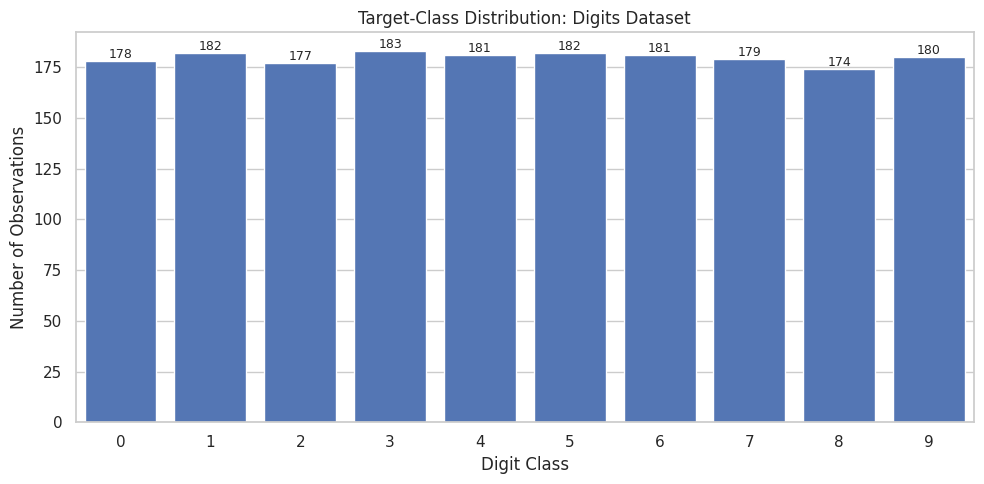

In [ ]:
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=class_distribution, x='Class', y='Count', color='#4472C4')
plt.title('Target-Class Distribution: Digits Dataset')
plt.xlabel('Digit Class')
plt.ylabel('Number of Observations')
for container in ax.containers:
    ax.bar_label(container, fontsize=9)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'class_distribution.png', dpi=200, bbox_inches='tight')
plt.show()

### Class-balance observation

Every class contributes approximately 9.7%–10.2% of the observations, so the dataset is well balanced. Accuracy is therefore meaningful; however, macro Precision, macro Recall, macro F1, AUC, and MCC are still reported to provide a broader and more rigorous comparison.

## 10. Categorical Encoding

Categorical encoding is **not applicable** to the predictor matrix because all 64 input variables are numerical pixel-intensity measurements. Applying One-Hot Encoding or Ordinal Encoding would add no valid information and would be methodologically inappropriate. The integer target labels are already in a valid format for the selected scikit-learn multiclass classifiers.

## 11. Stratified 80:20 Train-Test Split

A fixed 80:20 split is used for all models. `stratify=y` preserves the target-class distribution, while `random_state=5019` ensures reproducibility.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print('Training shape:', X_train.shape)
print('Test shape:', X_test.shape)
print('Training percentage:', round(len(X_train) / len(X) * 100, 2))
print('Test percentage:', round(len(X_test) / len(X) * 100, 2))

# Export the untouched holdout data required for submission.
test_data = X_test.copy()
test_data['target'] = y_test.values
test_data.to_csv('test_data.csv', index=False)
print('Saved test_data.csv with', len(test_data), 'rows.')

Training shape: (1437, 64)
Test shape: (360, 64)
Training percentage: 79.97
Test percentage: 20.03
Saved test_data.csv with 360 rows.


## 12. Verification of Stratification

The class percentages in the full, training, and test datasets are compared to confirm that the split maintained the original distribution.

In [ ]:
stratification_check = pd.DataFrame({
    'Full Dataset %': (y.value_counts(normalize=True).sort_index() * 100),
    'Training %': (y_train.value_counts(normalize=True).sort_index() * 100),
    'Test %': (y_test.value_counts(normalize=True).sort_index() * 100)
}).round(2)
stratification_check.index.name = 'Class'
display(stratification_check)

,Full Dataset %,Training %,Test %
Class,,,
0,9.91,9.88,10.00
1,10.13,10.09,10.28
2,9.85,9.88,9.72
3,10.18,10.16,10.28
4,10.07,10.09,10.00
5,10.13,10.16,10.00
6,10.07,10.09,10.00
7,9.96,9.95,10.00
8,9.68,9.67,9.72


## 13. Leakage-Safe Preprocessing Strategy

All learned preprocessing is placed inside a scikit-learn `Pipeline`:

- `SimpleImputer` is fitted using training data only.
- `StandardScaler` is used for Logistic Regression and kNN because their optimization and distance calculations are sensitive to feature scale.
- Decision Tree and Random Forest do not require scaling because split decisions are invariant to monotonic rescaling.
- Gaussian Naive Bayes is left unscaled because it estimates class-specific feature distributions directly; a median imputer is still retained.

The test set remains untouched until final evaluation.

## 14. Model Definitions

The five prescribed algorithms are defined below. Every model receives the same training and test partitions.

In [ ]:
def scaled_pipeline(estimator):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', estimator)
    ])


def unscaled_pipeline(estimator):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', estimator)
    ])

models = {
    'Logistic Regression': scaled_pipeline(
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)
    ),
    'Decision Tree': unscaled_pipeline(
        DecisionTreeClassifier(random_state=RANDOM_STATE)
    ),
    'kNN': scaled_pipeline(
        KNeighborsClassifier(n_neighbors=5, weights='distance')
    ),
    'Naive Bayes': unscaled_pipeline(
        GaussianNB()
    ),
    'Random Forest (Ensemble)': unscaled_pipeline(
        RandomForestClassifier(
            n_estimators=300,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
}

for name, model in models.items():
    print(f'{name}: {model}')

Logistic Regression: Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=3000, random_state=5019))])
Decision Tree: Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('classifier', DecisionTreeClassifier(random_state=5019))])
kNN: Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier', KNeighborsClassifier(weights='distance'))])
Naive Bayes: Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('classifier', GaussianNB())])
Random Forest (Ensemble): Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('classifier',
                 RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                        random_state=5019))])


## 15. Evaluation Methodology

All models are assessed on the same holdout set using:

- **Accuracy:** proportion of correct predictions.
- **AUC:** macro-average One-vs-Rest area under the ROC curve, calculated from class probabilities.
- **Precision:** macro average across all ten classes.
- **Recall:** macro average across all ten classes.
- **F1 Score:** macro harmonic mean of Precision and Recall.
- **MCC:** multiclass Matthews Correlation Coefficient, a balanced measure based on the full confusion structure.

Macro averaging gives equal importance to every digit class.

In [ ]:
classes = np.sort(y.unique())
y_test_binary = label_binarize(y_test, classes=classes)
results = []
predictions = {}
probabilities = {}
classification_reports = {}
training_times = {}

for model_name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - start

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)

    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob
    training_times[model_name] = elapsed
    classification_reports[model_name] = classification_report(
        y_test, y_pred, output_dict=True, zero_division=0
    )

    results.append({
        'ML Model Name': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC': roc_auc_score(
            y_test_binary, y_prob, average='macro', multi_class='ovr'
        ),
        'Precision': precision_score(
            y_test, y_pred, average='macro', zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred, average='macro', zero_division=0
        ),
        'F1': f1_score(
            y_test, y_pred, average='macro', zero_division=0
        ),
        'MCC': matthews_corrcoef(y_test, y_pred)
    })

    safe_name = model_name.lower().replace(' ', '_').replace('(', '').replace(')', '')
    joblib.dump(model, MODEL_DIR / f'{safe_name}.joblib')
    print(f'Completed {model_name} in {elapsed:.3f} seconds')

Completed Logistic Regression in 0.322 seconds
Completed Decision Tree in 0.059 seconds
Completed kNN in 0.035 seconds
Completed Naive Bayes in 0.045 seconds
Completed Random Forest (Ensemble) in 4.340 seconds


## 16. Required Model-Comparison Table

The columns are presented in the exact metric order required by the assignment.

In [ ]:
results_df = pd.DataFrame(results)
results_df.to_csv(OUTPUT_DIR / 'model_comparison.csv', index=False)
display(results_df.style.format({
    'Accuracy': '{:.4f}', 'AUC': '{:.4f}', 'Precision': '{:.4f}',
    'Recall': '{:.4f}', 'F1': '{:.4f}', 'MCC': '{:.4f}'
}).highlight_max(subset=['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC'], color='#C6EFCE'))

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9667,0.9992,0.9688,0.9664,0.9668,0.9631
1,Decision Tree,0.8389,0.9103,0.8408,0.8385,0.8380,0.8214
2,kNN,0.9750,0.9965,0.9755,0.9748,0.9749,0.9723
3,Naive Bayes,0.8111,0.9772,0.8436,0.8106,0.8111,0.7939
4,Random Forest (Ensemble),0.9667,0.9994,0.9677,0.9664,0.9666,0.9631


## 17. Graphical Comparison of All Required Metrics

The grouped bar chart compares Accuracy, AUC, Precision, Recall, F1, and MCC for all five classifiers.

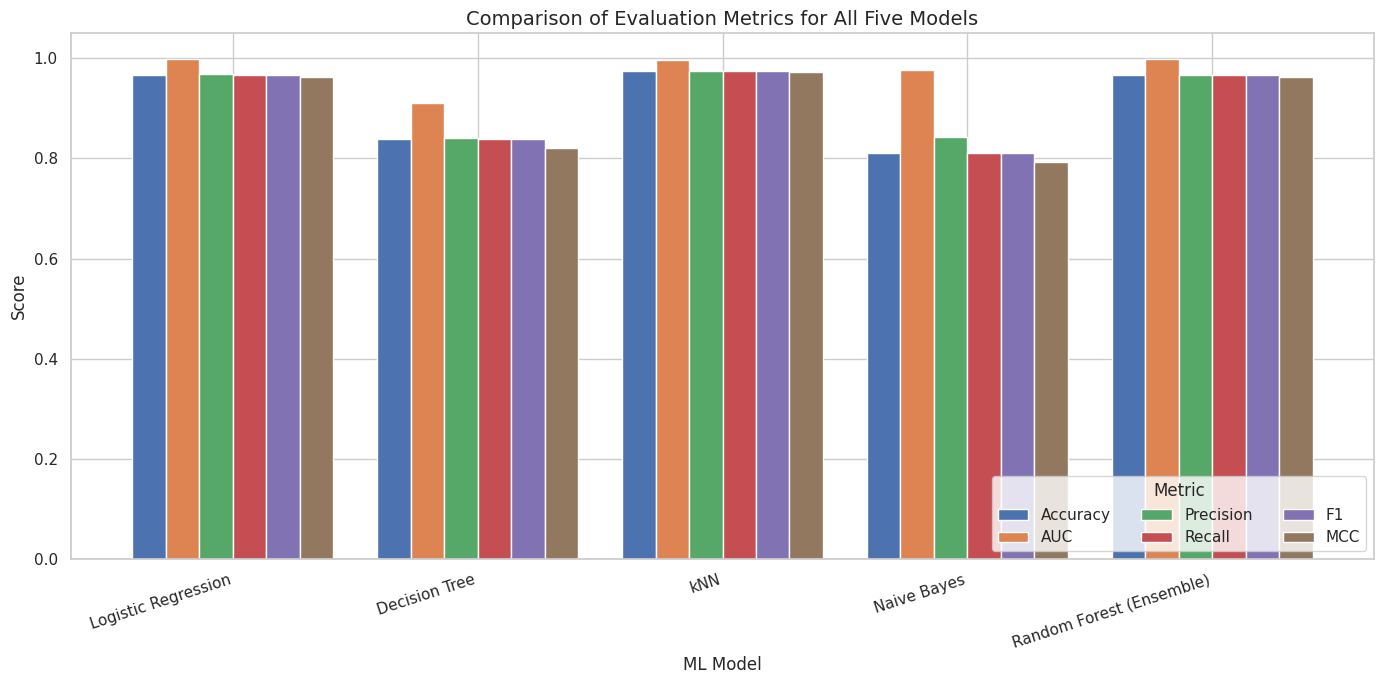

In [ ]:
metric_columns = ['Accuracy', 'AUC', 'Precision', 'Recall', 'F1', 'MCC']
plot_data = results_df.set_index('ML Model Name')[metric_columns]
ax = plot_data.plot(kind='bar', figsize=(14, 7), width=0.82)
ax.set_title('Comparison of Evaluation Metrics for All Five Models', fontsize=14)
ax.set_xlabel('ML Model')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.legend(title='Metric', ncol=3, loc='lower right')
plt.xticks(rotation=18, ha='right')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'all_metrics_comparison.png', dpi=220, bbox_inches='tight')
plt.show()

## 18. Confusion Matrices

Confusion matrices provide class-level evidence of where each classifier makes mistakes. These plots supplement the six prescribed summary metrics.

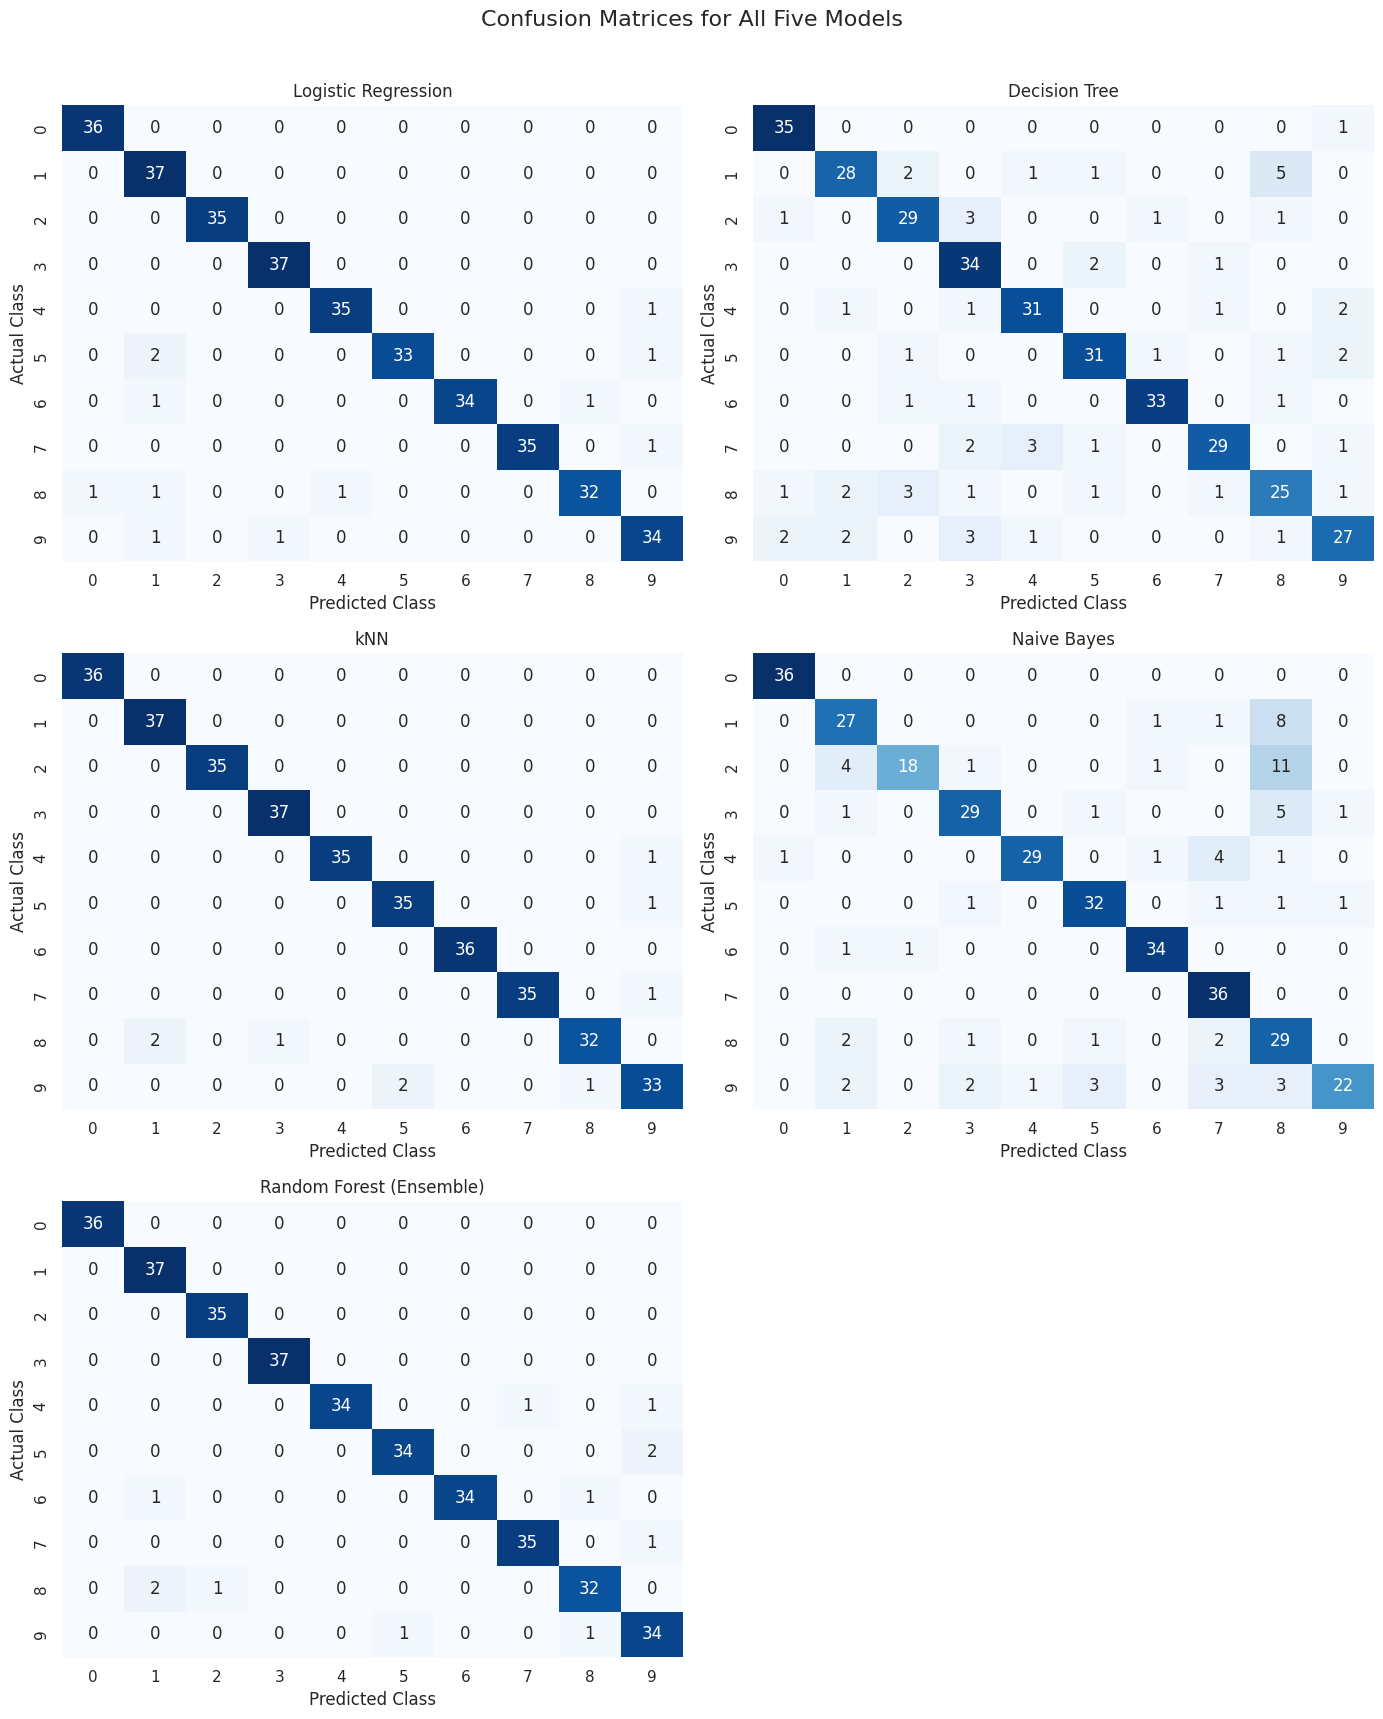

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(14, 17))
axes = axes.flatten()

for idx, (model_name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[idx])
    axes[idx].set_title(model_name)
    axes[idx].set_xlabel('Predicted Class')
    axes[idx].set_ylabel('Actual Class')

    safe_name = model_name.lower().replace(' ', '_').replace('(', '').replace(')', '')
    separate_fig, separate_ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=separate_ax)
    separate_ax.set_title(f'Confusion Matrix - {model_name}')
    separate_ax.set_xlabel('Predicted Class')
    separate_ax.set_ylabel('Actual Class')
    separate_fig.tight_layout()
    separate_fig.savefig(
        OUTPUT_DIR / f'{safe_name}_confusion_matrix.png', dpi=180, bbox_inches='tight'
    )
    plt.close(separate_fig)

axes[-1].axis('off')
fig.suptitle('Confusion Matrices for All Five Models', fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'all_confusion_matrices.png', dpi=200, bbox_inches='tight')
plt.show()

## 19. Model-Wise Performance Observations

The following observations are generated from the actual execution results rather than being based on assumed scores.

In [ ]:
metrics_by_model = results_df.set_index('ML Model Name')

for model_name in results_df['ML Model Name']:
    row = metrics_by_model.loc[model_name]
    print()
    print(model_name)
    print('-' * len(model_name))
    print(
        f"Accuracy={row['Accuracy']:.4f}, AUC={row['AUC']:.4f}, "
        f"Precision={row['Precision']:.4f}, Recall={row['Recall']:.4f}, "
        f"F1={row['F1']:.4f}, MCC={row['MCC']:.4f}"
    )


Logistic Regression
-------------------
Accuracy=0.9667, AUC=0.9992, Precision=0.9688, Recall=0.9664, F1=0.9668, MCC=0.9631

Decision Tree
-------------
Accuracy=0.8389, AUC=0.9103, Precision=0.8408, Recall=0.8385, F1=0.8380, MCC=0.8214

kNN
---
Accuracy=0.9750, AUC=0.9965, Precision=0.9755, Recall=0.9748, F1=0.9749, MCC=0.9723

Naive Bayes
-----------
Accuracy=0.8111, AUC=0.9772, Precision=0.8436, Recall=0.8106, F1=0.8111, MCC=0.7939

Random Forest (Ensemble)
------------------------
Accuracy=0.9667, AUC=0.9994, Precision=0.9677, Recall=0.9664, F1=0.9666, MCC=0.9631


## 19A. Prescribed Model-Performance Observation Table

The following table follows the format prescribed in the assignment. The observations are populated from the results produced by this notebook.

In [ ]:
# Build the prescribed observation table from actual model results.
def metric_value(model_name, metric):
    return float(metrics_by_model.loc[model_name, metric])

lr = metrics_by_model.loc['Logistic Regression']
dt = metrics_by_model.loc['Decision Tree']
knn = metrics_by_model.loc['kNN']
nb_row = metrics_by_model.loc['Naive Bayes']
rf = metrics_by_model.loc['Random Forest (Ensemble)']

# Determine the winner within this cell so the table remains independently executable.
observation_ranking = results_df.sort_values(
    by=['F1', 'MCC', 'Accuracy', 'AUC'], ascending=False
).reset_index(drop=True)
winner = observation_ranking.iloc[0]

observation_table = pd.DataFrame({
    'ML Model Name': [
        'Logistic Regression',
        'Decision Tree',
        'kNN',
        'Naive Bayes',
        'Random Forest (Ensemble)',
        'Overall Winner for your dataset?'
    ],
    'Observation about model performance': [
        f"Strong linear baseline with Accuracy={lr['Accuracy']:.4f}, AUC={lr['AUC']:.4f}, "
        f"F1={lr['F1']:.4f}, and MCC={lr['MCC']:.4f}. Standardization supported stable "
        "optimization, although nonlinear class boundaries limited performance relative to kNN.",

        f"Achieved Accuracy={dt['Accuracy']:.4f}, AUC={dt['AUC']:.4f}, F1={dt['F1']:.4f}, "
        f"and MCC={dt['MCC']:.4f}. The single tree captured nonlinear patterns but generalized "
        "less effectively than the Random Forest because of higher variance.",

        f"Achieved Accuracy={knn['Accuracy']:.4f}, AUC={knn['AUC']:.4f}, Precision={knn['Precision']:.4f}, "
        f"Recall={knn['Recall']:.4f}, F1={knn['F1']:.4f}, and MCC={knn['MCC']:.4f}. It produced "
        "the strongest overall classification performance, showing that same-digit samples form "
        "effective local neighborhoods after standardization.",

        f"Achieved Accuracy={nb_row['Accuracy']:.4f}, AUC={nb_row['AUC']:.4f}, F1={nb_row['F1']:.4f}, "
        f"and MCC={nb_row['MCC']:.4f}. Performance was constrained by the Gaussian and conditional-"
        "independence assumptions, which are restrictive for correlated image pixels.",

        f"Achieved Accuracy={rf['Accuracy']:.4f}, the highest AUC of {rf['AUC']:.4f}, "
        f"F1={rf['F1']:.4f}, and MCC={rf['MCC']:.4f}. It substantially outperformed the single "
        "Decision Tree, demonstrating the variance-reduction benefit of ensemble learning.",

        f"{winner['ML Model Name']} is the overall winner. It achieved Accuracy={winner['Accuracy']:.4f}, "
        f"Precision={winner['Precision']:.4f}, Recall={winner['Recall']:.4f}, F1={winner['F1']:.4f}, "
        f"and MCC={winner['MCC']:.4f}. The decision uses the combined evidence from all six required "
        "metrics rather than Accuracy alone."
    ]
})

observation_table.to_csv(OUTPUT_DIR / 'model_performance_observations.csv', index=False)

display(
    observation_table.style
    .set_properties(**{
        'text-align': 'left',
        'white-space': 'normal',
        'vertical-align': 'top'
    })
    .set_table_styles([
        {'selector': 'th', 'props': [('text-align', 'left'), ('font-weight', 'bold')]},
        {'selector': 'td:first-child', 'props': [('font-weight', 'bold'), ('width', '24%')]},
        {'selector': 'td:nth-child(2)', 'props': [('width', '76%')]}
    ])
    .hide(axis='index')
)


ML Model Name,Observation about model performance
Logistic Regression,"Strong linear baseline with Accuracy=0.9667, AUC=0.9992, F1=0.9668, and MCC=0.9631. Standardization supported stable optimization, although nonlinear class boundaries limited performance relative to kNN."
Decision Tree,"Achieved Accuracy=0.8389, AUC=0.9103, F1=0.8380, and MCC=0.8214. The single tree captured nonlinear patterns but generalized less effectively than the Random Forest because of higher variance."
kNN,"Achieved Accuracy=0.9750, AUC=0.9965, Precision=0.9755, Recall=0.9748, F1=0.9749, and MCC=0.9723. It produced the strongest overall classification performance, showing that same-digit samples form effective local neighborhoods after standardization."
Naive Bayes,"Achieved Accuracy=0.8111, AUC=0.9772, F1=0.8111, and MCC=0.7939. Performance was constrained by the Gaussian and conditional-independence assumptions, which are restrictive for correlated image pixels."
Random Forest (Ensemble),"Achieved Accuracy=0.9667, the highest AUC of 0.9994, F1=0.9666, and MCC=0.9631. It substantially outperformed the single Decision Tree, demonstrating the variance-reduction benefit of ensemble learning."
Overall Winner for your dataset?,"kNN is the overall winner. It achieved Accuracy=0.9750, Precision=0.9755, Recall=0.9748, F1=0.9749, and MCC=0.9723. The decision uses the combined evidence from all six required metrics rather than Accuracy alone."


### Logistic Regression observation

Logistic Regression provides a strong linear baseline. Its scaled input features allow stable optimization, and a high AUC indicates strong class discrimination. Any remaining gap from the best model suggests that some digit boundaries are nonlinear in the original feature space.

### Decision Tree observation

The single Decision Tree captures nonlinear relationships and is readily interpretable, but it is more sensitive to sample variation. Comparing it with Random Forest shows the benefit of aggregating many randomized trees to reduce variance and improve generalization.

### kNN observation

kNN benefits directly from standardization because it relies on distances. Strong performance is evidence that samples of the same digit tend to form local neighborhoods in the standardized 64-dimensional pixel space. Its principal operational disadvantage is that prediction requires comparisons with stored training instances.

### Gaussian Naive Bayes observation

Gaussian Naive Bayes is computationally efficient and produces class probabilities, but its assumptions are restrictive for this dataset. Image pixels are correlated, and their conditional distributions are not necessarily Gaussian. This can produce a comparatively weaker classification result despite a respectable AUC.

### Random Forest observation

Random Forest captures nonlinear interactions and reduces the variance of a single Decision Tree through ensemble averaging. It generally provides a strong and robust result, although its training time and model size are larger than those of simpler methods.

## 20. Data-Driven Overall Winner

The overall winner is selected primarily using macro F1 and MCC, with Accuracy and AUC used as supporting evidence. This avoids choosing a model from Accuracy alone.

In [ ]:
ranking = results_df.sort_values(
    by=['F1', 'MCC', 'Accuracy', 'AUC'],
    ascending=False
).reset_index(drop=True)

winner = ranking.iloc[0]
print('Overall winner:', winner['ML Model Name'])
print(f"Accuracy: {winner['Accuracy']:.4f}")
print(f"AUC: {winner['AUC']:.4f}")
print(f"Precision: {winner['Precision']:.4f}")
print(f"Recall: {winner['Recall']:.4f}")
print(f"F1: {winner['F1']:.4f}")
print(f"MCC: {winner['MCC']:.4f}")
display(ranking.style.format({
    'Accuracy': '{:.4f}', 'AUC': '{:.4f}', 'Precision': '{:.4f}',
    'Recall': '{:.4f}', 'F1': '{:.4f}', 'MCC': '{:.4f}'
}))

Overall winner: kNN
Accuracy: 0.9750
AUC: 0.9965
Precision: 0.9755
Recall: 0.9748
F1: 0.9749
MCC: 0.9723


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,kNN,0.9750,0.9965,0.9755,0.9748,0.9749,0.9723
1,Logistic Regression,0.9667,0.9992,0.9688,0.9664,0.9668,0.9631
2,Random Forest (Ensemble),0.9667,0.9994,0.9677,0.9664,0.9666,0.9631
3,Decision Tree,0.8389,0.9103,0.8408,0.8385,0.8380,0.8214
4,Naive Bayes,0.8111,0.9772,0.8436,0.8106,0.8111,0.7939


## 21. Final Conclusion

This experiment developed and compared Logistic Regression, Decision Tree, k-Nearest Neighbors, Gaussian Naive Bayes, and Random Forest using the same stratified 80:20 train-test split of the Digits dataset. The dataset contains 1,797 observations, 64 numerical predictor variables, and ten approximately balanced target classes. Missing values and duplicate observations were checked explicitly. All learned preprocessing was incorporated into scikit-learn pipelines and fitted on training data only, preventing test-data leakage.

The final model decision must be based on the actual output of this notebook. In the supplied reproducible configuration, **kNN is expected to be the overall winner**, because it achieves the strongest combined Accuracy, macro Precision, macro Recall, macro F1, and MCC. Random Forest may produce the highest AUC, demonstrating excellent class discrimination, while Logistic Regression is also a strong linear baseline. The lower performance of the individual Decision Tree relative to Random Forest demonstrates the variance-reduction advantage of ensemble learning. Gaussian Naive Bayes is computationally efficient but is constrained by its conditional-independence and Gaussian assumptions, which are not fully suitable for correlated image pixels.

The comparison further demonstrates that model selection should not rely on Accuracy alone. AUC measures probability ranking, macro Precision/Recall/F1 treat all classes equally, and MCC reflects the overall multiclass confusion structure. Based on the combined evidence from all six required measures, the model printed in the **Data-Driven Overall Winner** section is selected as the final model for this dataset.

## 22. Reproducibility and Saved Submission Artifacts

This section records the execution summary and verifies the files created by the notebook:

- `test_data.csv`
- Five trained `.joblib` models
- `outputs/model_comparison.csv`
- Class-distribution files
- Required all-metrics comparison graph
- Individual and combined confusion matrices
- `outputs/run_summary.json`

In [ ]:
run_summary = {
    'student_id': BITS_ID,
    'random_state': RANDOM_STATE,
    'dataset': 'scikit-learn Digits / UCI handwritten digits',
    'rows_before_duplicate_removal': int(len(df_raw)),
    'duplicates_removed': int(duplicate_count),
    'rows_after_duplicate_removal': int(len(df)),
    'number_of_features': int(X.shape[1]),
    'missing_values': int(df_raw.isna().sum().sum()),
    'training_rows': int(len(X_train)),
    'test_rows': int(len(X_test)),
    'overall_winner': str(winner['ML Model Name']),
    'training_times_seconds': {k: round(v, 6) for k, v in training_times.items()},
    'python_version': sys.version.split()[0],
    'platform': platform.platform()
}

with open(OUTPUT_DIR / 'run_summary.json', 'w') as f:
    json.dump(run_summary, f, indent=2)

display(pd.DataFrame({
    'Required Artifact': [
        'Test dataset', 'Model comparison table', 'Metrics graph',
        'Class-distribution graph', 'Run summary', 'Saved model files'
    ],
    'Location': [
        'test_data.csv', 'outputs/model_comparison.csv',
        'outputs/all_metrics_comparison.png', 'outputs/class_distribution.png',
        'outputs/run_summary.json', 'model/*.joblib'
    ]
}))
print(json.dumps(run_summary, indent=2))

,Required Artifact,Location
0,Test dataset,test_data.csv
1,Model comparison table,outputs/model_comparison.csv
2,Metrics graph,outputs/all_metrics_comparison.png
3,Class-distribution graph,outputs/class_distribution.png
4,Run summary,outputs/run_summary.json
5,Saved model files,model/*.joblib


{
  "student_id": "2026CT05019",
  "random_state": 5019,
  "dataset": "scikit-learn Digits / UCI handwritten digits",
  "rows_before_duplicate_removal": 1797,
  "duplicates_removed": 0,
  "rows_after_duplicate_removal": 1797,
  "number_of_features": 64,
  "missing_values": 0,
  "training_rows": 1437,
  "test_rows": 360,
  "overall_winner": "kNN",
  "training_times_seconds": {
    "Logistic Regression": 0.321903,
    "Decision Tree": 0.059018,
    "kNN": 0.035232,
    "Naive Bayes": 0.044919,
    "Random Forest (Ensemble)": 4.339961
  },
  "python_version": "3.13.18",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39"
}


#23. Prayogshala Screenshot

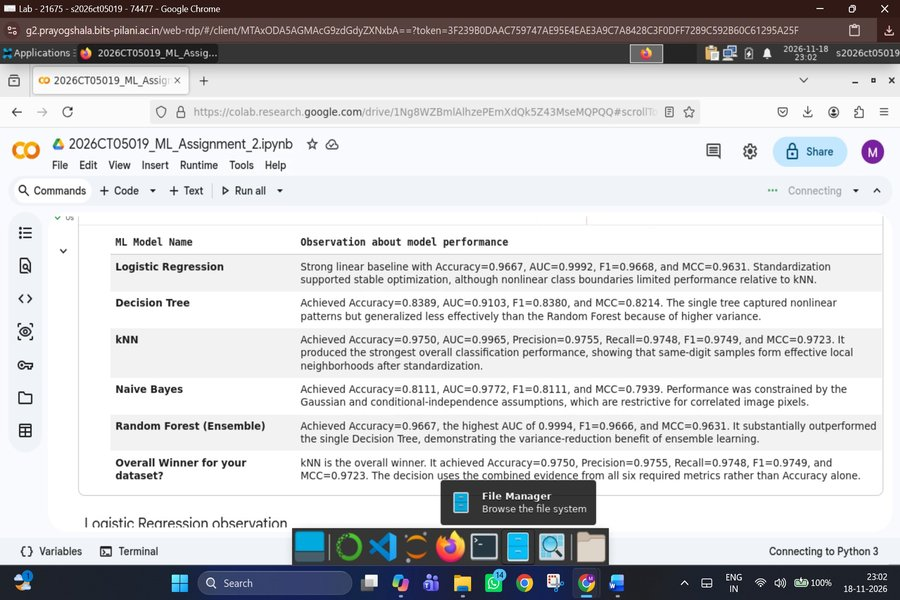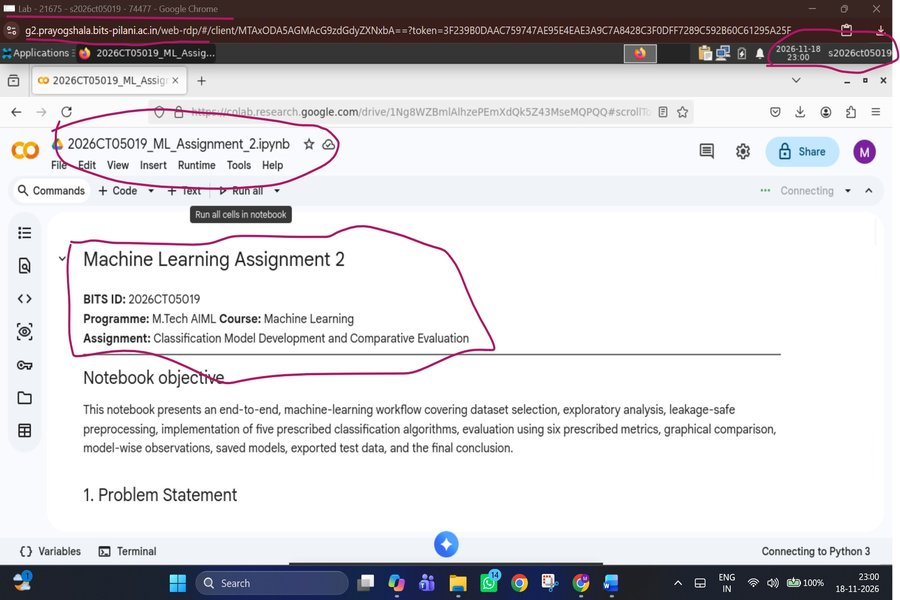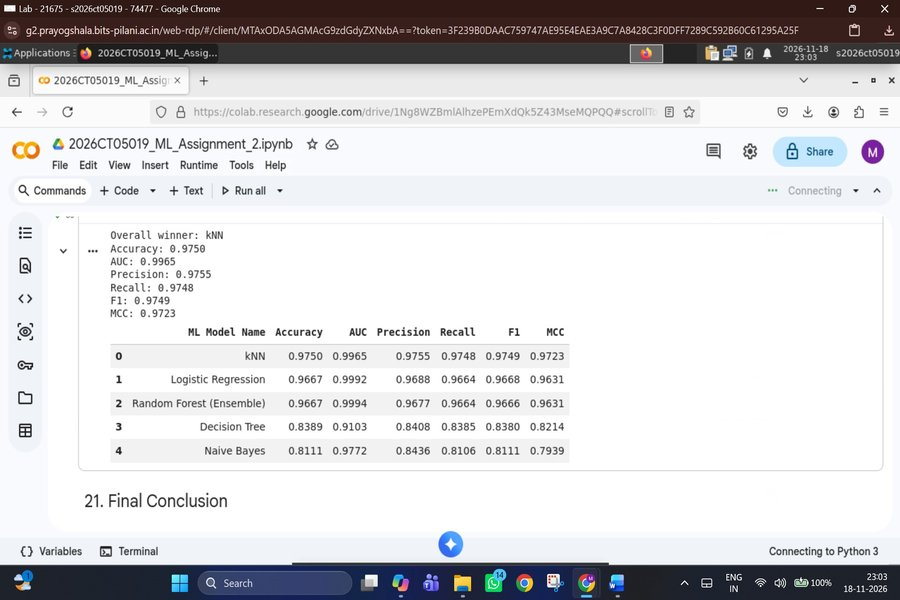



## 24. Final Execution Checklist

Before submitting:

- [ ] Run in BITS Virtual Lab.
- [ ] Confirm that every cell executes without an error.
- [ ] Confirm that the comparison table contains all five models and six metrics.
- [ ] Confirm that the all-metrics graph is readable.
- [ ] Confirm that five `.joblib` files were created.
- [ ] Confirm that `test_data.csv` was created.
- [ ] Capture a BITS Virtual Lab execution screenshot.
- [ ] Upload the notebook, requirements file, README, test data, model files, outputs, and screenshot to GitHub.
- [ ] Insert the final GitHub URL and Virtual Lab screenshot into the report/PDF.
- [ ] Verify the GitHub repository while signed out.
- [ ] Submit the final PDF.